# 01 · Setup + SFT (Tasks 1 & 3)
**Settings:** Accelerator **GPU T4 x2** · Internet **On** · run with **Save Version → Save & Run All (Commit)** so it keeps going with the browser closed.

**Needs:** nothing. **Produces:** `outputs/sft/{best,final,metrics.jsonl,data/}` (~1.5 h).

In [1]:
# Code repo (public, or add a GitHub token as a Kaggle secret if private)
REPO_URL = "https://github.com/NifraWahaj/cs5323_PA2.git"
BRANCH = "main"

import os, subprocess, sys
REPO = "/kaggle/working/sprout"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, REPO], check=True)
else:
    subprocess.run(["git", "-C", REPO, "pull", "-q"], check=True)
os.chdir(REPO)
sys.path.insert(0, REPO)
print(subprocess.run(["git", "log", "--oneline", "-1"], capture_output=True, text=True).stdout)

14109c4 Fix SFT validation OOM on T4; fail notebooks loudly when training fails



In [2]:
# Kaggle's PyTorch already matches the GPU runtime: do NOT reinstall torch.
!python -m pip uninstall -y -q torchao || true
!python -m pip install -q "transformers>=4.43.0,<5" "datasets>=2.18,<5" huggingface_hub accelerate tqdm pyyaml sentencepiece safetensors pytest
!python -m pip install -q -e . --no-deps

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 113.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 30.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 83.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for sproutlm (pyproject.toml) ... done


In [3]:
!nvidia-smi --query-gpu=index,name,memory.total --format=csv
import torch, transformers, datasets
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__)
print("GPUs visible:", torch.cuda.device_count())
assert torch.cuda.device_count() == 2, "Set Accelerator to GPU T4 x2"

index, name, memory.total [MiB]
0, Tesla T4, 15360 MiB
1, Tesla T4, 15360 MiB
torch 2.11.0+cu128 | transformers 4.57.6 | datasets 4.8.5
GPUs visible: 2


## Public adapter tests + our edge-case tests (offline, CPU)

In [4]:
!PYTHONPATH=. python -m pytest -q tests

.................                                                        [100%]
17 passed in 4.86s


## Freeze the fixed AlpacaEval subset now (300 prompts, seed 42) so every later notebook uses the same file

In [5]:
from sproutlm.generate import ensure_alpaca_subset
import json, shutil, os
p = ensure_alpaca_subset()
os.makedirs("/kaggle/working/outputs/eval_sets", exist_ok=True)
shutil.copy(p, "/kaggle/working/outputs/eval_sets/")
shutil.copy("eval_sets/hh_rlhf_eval_300_seed42.json", "/kaggle/working/outputs/eval_sets/")
print(len(json.load(open(p))), "alpaca prompts ->", p)

300 alpaca prompts -> /kaggle/working/sprout/eval_sets/alpaca_eval_300_seed42.json


## SFT on both T4s (DDP via torchrun)
Global batch = 2 per GPU × 2 GPUs × 8 accumulation = 32. Override any config key with `key=value`.

In [6]:
!PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True NCCL_P2P_DISABLE=1 TOKENIZERS_PARALLELISM=false torchrun --nproc_per_node 2 -m sproutlm.sft_loop \
    --config configs/sft.yaml output_dir=/kaggle/working/outputs/sft
import os
assert os.path.exists("/kaggle/working/outputs/sft/best/sprout_note.json"), "SFT FAILED - read the log above; do not attach this version to 02"

W1015 07:40:21.141000 157 torch/distributed/run.py:851] 
W1015 07:40:21.141000 157 torch/distributed/run.py:851] *****************************************
W1015 07:40:21.141000 157 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1015 07:40:21.141000 157 torch/distributed/run.py:851] *****************************************
tokenizer_config.json: 7.23kB [00:00, 31.6MB/s]
vocab.json: 2.78MB [00:00, 110MB/s]
merges.txt: 1.67MB [00:00, 142MB/s]
tokenizer.json: 7.03MB [00:00, 200MB/s]
README.md: 3.90kB [00:00, 23.5MB/s]
data/train_sft-00000-of-00003-a3ecf92756(…): 100%|█| 244M/244M [00:01<00:00, 170
data/train_sft-00001-of-00003-0a1804bcb6(…): 100%|█| 244M/244M [00:02<00:00, 108
data/train_sft-00002-of-00003-ee46ed25cf(…): 100%|█| 244M/244M [00:01<00:00, 126
data/test_sft-00000-of-00001-f7dfac4afe5(…

[sprout-plots] /kaggle/working/outputs/plots/sft.png


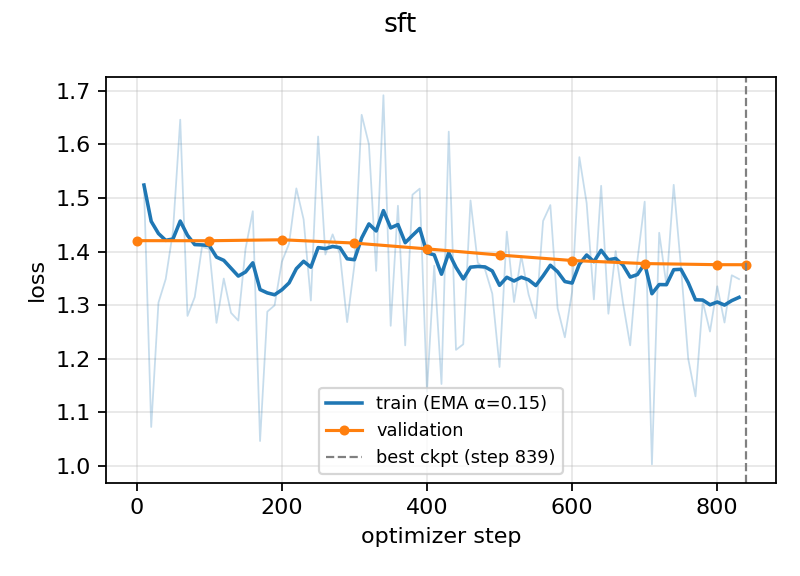

In [7]:
!pip install -q matplotlib
!python -m sproutlm.plots --run /kaggle/working/outputs/sft --out /kaggle/working/outputs/plots
from IPython.display import Image; Image("/kaggle/working/outputs/plots/sft.png")

In [8]:
!cat /kaggle/working/outputs/sft/best/sprout_note.json

{
  "step": 839,
  "val_loss": 1.3755343536190867,
  "base": "Qwen/Qwen2.5-0.5B"
}

In [9]:
# Archive this stage (easier to download/attach), then: Save Version -> "Save & Run All (Commit)".
!cd /kaggle/working && zip -qr sft_run_outputs.zip outputs/sft/metrics.jsonl outputs/sft/config_used.yaml outputs/plots outputs/eval_sets && ls -lh /kaggle/working && du -sh /kaggle/working/outputs/*

total 296K
-rw-r--r--  1 root root 171K Oct 15 08:45 __notebook__.ipynb
drwxr-xr-x  5 root root 4.0K Oct 15 08:45 outputs
-rw-r--r--  1 root root 113K Oct 15 08:45 sft_run_outputs.zip
drwxr-xr-x 15 root root 4.0K Oct 15 07:40 sprout
184K	/kaggle/working/outputs/eval_sets
84K	/kaggle/working/outputs/plots
2.5G	/kaggle/working/outputs/sft
